# Decision-Level Fusion

CNN + dlib geometry probability fusion.

## 1. Imports and reproducibility

Import the libraries used for loading the models, processing images, evaluating predictions, and saving results.

In [1]:
from pathlib import Path
import json
import warnings

import cv2
import joblib
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.22.0-rc0
NumPy: 2.5.4


## 1. Project paths

In [2]:
def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (
            (candidate / "data" / "FER-2013").is_dir()
            and (candidate / "models").is_dir()
            and (candidate / "results").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "MiniProject root not found. Open this notebook from MiniProject or a subfolder."
    )


PROJECT_DIR = find_project_root()
DATA_DIR = PROJECT_DIR / "data" / "FER-2013"
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
PREDICTION_DIR = RESULTS_DIR / "predictions"
MANIFEST_DIR = DATA_DIR.parent / "manifests"

cnn_candidates = [
    MODEL_DIR / "appearance_cnn_fixed.keras",
    MODEL_DIR / "appearance_cnn.keras",
]
CNN_MODEL_PATH = next((path for path in cnn_candidates if path.is_file()), None)

GEOMETRY_MODEL_PATH = MODEL_DIR / "dlib_geometry_model_expanded.joblib"
GEOMETRY_VAL_PATH = PREDICTION_DIR / "geometry_predictions_validation.csv"
GEOMETRY_TEST_PATH = PREDICTION_DIR / "geometry_predictions_test.csv"
GEOMETRY_MANIFEST_PATH = MANIFEST_DIR / "fer2013_geometry_manifest.csv"
CNN_VALIDATION_MANIFEST_PATH = MANIFEST_DIR / "cnn_validation_manifest.csv"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_DIR)
print("CNN:", CNN_MODEL_PATH or "MISSING")
print("Geometry model:", GEOMETRY_MODEL_PATH)
print("Geometry validation CSV:", GEOMETRY_VAL_PATH)
print("Geometry test CSV:", GEOMETRY_TEST_PATH)
print("Geometry manifest:", GEOMETRY_MANIFEST_PATH)
print("CNN validation manifest:", CNN_VALIDATION_MANIFEST_PATH)

Project: c:\Users\HP\Documents\MiniProject
CNN: c:\Users\HP\Documents\MiniProject\models\appearance_cnn_fixed.keras
Geometry model: c:\Users\HP\Documents\MiniProject\models\dlib_geometry_model_expanded.joblib
Geometry validation CSV: c:\Users\HP\Documents\MiniProject\results\predictions\geometry_predictions_validation.csv
Geometry test CSV: c:\Users\HP\Documents\MiniProject\results\predictions\geometry_predictions_test.csv
Geometry manifest: c:\Users\HP\Documents\MiniProject\data\manifests\fer2013_geometry_manifest.csv
CNN validation manifest: c:\Users\HP\Documents\MiniProject\data\manifests\cnn_validation_manifest.csv


## 2. Load models

In [3]:
required_paths = [
    GEOMETRY_MODEL_PATH,
    GEOMETRY_VAL_PATH,
    GEOMETRY_TEST_PATH,
    GEOMETRY_MANIFEST_PATH,
]
missing_paths = [p for p in required_paths if not p.is_file()]
if CNN_MODEL_PATH is None:
    missing_paths.append(MODEL_DIR / "appearance_cnn_fixed.keras or appearance_cnn.keras")
if missing_paths:
    raise FileNotFoundError(
        "Missing required project files:\n" +
        "\n".join(str(p) for p in missing_paths)
    )

cnn_model = tf.keras.models.load_model(CNN_MODEL_PATH, compile=False)
import sklearn
print("scikit-learn:", sklearn.__version__)
print("Note: the geometry artifact was originally saved with scikit-learn 1.9.1.")

geometry_artifact = joblib.load(GEOMETRY_MODEL_PATH)

geometry_model = geometry_artifact["model"]
geometry_scaler = geometry_artifact["scaler"]
GEOMETRY_CLASSES = [str(x) for x in geometry_artifact["emotion_classes"]]
ESTIMATOR_CLASSES = [str(x) for x in geometry_model.classes_]
if GEOMETRY_CLASSES != ESTIMATOR_CLASSES:
    raise ValueError(
        "The geometry artifact class order differs from the estimator class order. "
        "Check the probability-column order before fusion."
    )
FEATURE_COLUMNS = list(geometry_artifact["feature_columns"])

print("CNN model:", CNN_MODEL_PATH.name)
print("CNN input:", cnn_model.input_shape)
print("CNN output:", cnn_model.output_shape)
print("Geometry estimator:", type(geometry_model).__name__)
print("Geometry features:", len(FEATURE_COLUMNS))

scikit-learn: 1.9.1
Note: the geometry artifact was originally saved with scikit-learn 1.9.1.
CNN model: appearance_cnn_fixed.keras
CNN input: (None, 48, 48, 1)
CNN output: (None, 7)
Geometry estimator: RandomForestClassifier
Geometry features: 25


## 3. Check classes and feature count

In [4]:
CNN_CLASSES = [
    "angry", "disgust", "fear", "happy",
    "sad", "surprise", "neutral"
]

if tuple(cnn_model.input_shape[1:]) != (48, 48, 1):
    raise ValueError(f"Expected CNN input (48, 48, 1), got {cnn_model.input_shape}")

if int(cnn_model.output_shape[-1]) != len(CNN_CLASSES):
    raise ValueError("CNN output count does not match the seven emotion classes.")

if len(FEATURE_COLUMNS) != 25:
    raise ValueError(f"Expected 25 geometry features, found {len(FEATURE_COLUMNS)}.")

estimator_classes = [str(x) for x in geometry_model.classes_]
if set(estimator_classes) != set(CNN_CLASSES):
    raise ValueError(
        f"Geometry classes {estimator_classes} do not match CNN classes {CNN_CLASSES}"
    )

geometry_to_cnn_indices = [
    estimator_classes.index(label) for label in CNN_CLASSES
]

print("CNN class order:", CNN_CLASSES)
print("Geometry class order:", estimator_classes)
print("Geometry-to-CNN column indices:", geometry_to_cnn_indices)
print("Feature count:", len(FEATURE_COLUMNS))

CNN class order: ['angry', 'disgust', 'fear', 'happy', 'sad', 'surprise', 'neutral']
Geometry class order: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Geometry-to-CNN column indices: [0, 1, 2, 3, 5, 6, 4]
Feature count: 25


## 4. Check dataset

In [5]:
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

for split_name, split_dir in [("Train", TRAIN_DIR), ("Test", TEST_DIR)]:
    if not split_dir.is_dir():
        raise FileNotFoundError(f"Dataset split not found: {split_dir}")

    print(f"\n{split_name} set")
    total = 0
    for emotion in CNN_CLASSES:
        emotion_dir = split_dir / emotion
        if not emotion_dir.is_dir():
            raise FileNotFoundError(f"Missing emotion folder: {emotion_dir}")
        count = sum(
            1 for p in emotion_dir.iterdir()
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        )
        total += count
        print(f"{emotion:10s}: {count}")
    print("Total:", total)


Train set
angry     : 3995
disgust   : 436
fear      : 4097
happy     : 7215
sad       : 4830
surprise  : 3171
neutral   : 4965
Total: 28709

Test set
angry     : 958
disgust   : 111
fear      : 1024
happy     : 1774
sad       : 1247
surprise  : 831
neutral   : 1233
Total: 7178


## 5. Load geometry predictions

In [6]:
geometry_val = pd.read_csv(GEOMETRY_VAL_PATH)
geometry_test = pd.read_csv(GEOMETRY_TEST_PATH)
geometry_manifest = pd.read_csv(GEOMETRY_MANIFEST_PATH)

required_prediction_columns = {
    "image", "emotion", "geometry_available",
    *[f"p_{emotion}" for emotion in GEOMETRY_CLASSES]
}
for split_name, frame in [("validation", geometry_val), ("test", geometry_test)]:
    missing = required_prediction_columns - set(frame.columns)
    if missing:
        raise ValueError(f"{split_name} geometry CSV is missing: {sorted(missing)}")

required_manifest_columns = {"partition", "image", "emotion"}
missing = required_manifest_columns - set(geometry_manifest.columns)
if missing:
    raise ValueError(f"Geometry manifest is missing columns: {sorted(missing)}")

for split_name, frame in [("validation", geometry_val), ("test", geometry_test)]:
    frame["image"] = frame["image"].astype(str).str.replace("\\\\", "/", regex=False)
    available = frame["geometry_available"].astype(str).str.strip().str.lower()
    allowed = {"true", "false", "1", "0", "yes", "no"}
    if not available.isin(allowed).all():
        raise ValueError(f"Invalid geometry_available values in {split_name} CSV.")
    frame["geometry_available"] = available.isin({"true", "1", "yes"})
    if frame["image"].duplicated().any():
        raise ValueError(f"Duplicate image paths in {split_name} geometry CSV.")

geometry_manifest["image"] = (
    geometry_manifest["image"].astype(str).str.replace("\\\\", "/", regex=False)
)
geometry_manifest["partition"] = (
    geometry_manifest["partition"].astype(str).str.strip().str.lower()
)

# The test CSV must include every FER-2013 test image, including dlib failures,
# so CNN fallback and geometry coverage use the correct denominator.
test_image_paths = {
    path.relative_to(DATA_DIR).as_posix()
    for emotion_dir in TEST_DIR.iterdir()
    if emotion_dir.is_dir()
    for path in emotion_dir.iterdir()
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
}
csv_test_paths = set(geometry_test["image"])
if csv_test_paths != test_image_paths:
    raise ValueError(
        "geometry_predictions_test.csv must contain every test image exactly once, "
        "including rows where geometry_available is False. "
        f"CSV rows={len(csv_test_paths)}, dataset test images={len(test_image_paths)}."
    )

print("Validation rows:", len(geometry_val))
print("Test rows:", len(geometry_test))
print("Geometry-covered test rows:", int(geometry_test["geometry_available"].sum()))
print("Test geometry coverage:", f"{geometry_test['geometry_available'].mean() * 100:.2f}%")

Validation rows: 5742
Test rows: 7178
Geometry-covered test rows: 5378
Test geometry coverage: 74.92%


## 6. Verify CNN validation manifest

Use the exact validation image paths from the original CNN training run. Do not recreate the split.

In [7]:
if not CNN_VALIDATION_MANIFEST_PATH.is_file():
    raise FileNotFoundError(
        "Missing exact CNN validation manifest: "
        f"{CNN_VALIDATION_MANIFEST_PATH}"
    )

cnn_validation_manifest = pd.read_csv(CNN_VALIDATION_MANIFEST_PATH)
if "image" not in cnn_validation_manifest.columns:
    raise ValueError("CNN validation manifest must contain an 'image' column.")

cnn_validation_paths = set(
    cnn_validation_manifest["image"].dropna().astype(str)
    .str.replace("\\\\", "/", regex=False)
)
if not cnn_validation_paths:
    raise ValueError("CNN validation manifest is empty.")

geometry_validation_paths = set(
    geometry_manifest.loc[
        geometry_manifest["partition"].isin({"validation", "val"}), "image"
    ].dropna().astype(str)
)
shared_validation_paths = cnn_validation_paths & geometry_validation_paths

print("CNN validation images:", len(cnn_validation_paths))
print("Geometry validation images:", len(geometry_validation_paths))
print("Shared validation images:", len(shared_validation_paths))

if not shared_validation_paths:
    raise ValueError("No matching CNN/geometry validation images. Check manifest paths.")

CNN validation images: 2871
Geometry validation images: 5742
Shared validation images: 1843


## 7. CNN preprocessing

This preprocessing must exactly match the CNN training pipeline and `fusion_model.py`.

In [9]:
def preprocess_fer_image(image_path: Path) -> np.ndarray:
    image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    image = cv2.resize(image, (48, 48), interpolation=cv2.INTER_AREA)
    image = cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX)
    image = image.astype(np.float32)[..., np.newaxis]
    return image


def generate_cnn_predictions(frame: pd.DataFrame, batch_size: int = 64) -> pd.DataFrame:
    if frame.empty:
        raise ValueError("Cannot generate CNN predictions for an empty dataframe.")

    result = frame.copy().reset_index(drop=True)
    all_probabilities = []

    for start in range(0, len(result), batch_size):
        batch = result.iloc[start:start + batch_size]
        batch_images = np.stack([
            preprocess_fer_image(DATA_DIR / relative_path)
            for relative_path in batch["image"]
        ])

        batch_probabilities = cnn_model.predict(batch_images, verbose=0)
        all_probabilities.append(batch_probabilities)

        processed = min(start + batch_size, len(result))
        print(f"Processed {processed}/{len(result)} images", end="\r")

    probabilities = np.vstack(all_probabilities)

    if probabilities.shape != (len(result), len(CNN_CLASSES)):
        raise ValueError(f"Unexpected CNN probability shape: {probabilities.shape}")

    if not np.all(np.isfinite(probabilities)):
        raise ValueError("CNN produced NaN or infinite probabilities.")

    for index, emotion in enumerate(CNN_CLASSES):
        result[f"cnn_{emotion}"] = probabilities[:, index]

    print("\nCNN prediction generation complete.")
    return result

## 8. Generate CNN predictions

In [10]:
cnn_val = generate_cnn_predictions(geometry_val)
cnn_test = generate_cnn_predictions(geometry_test)

cnn_val_path = PREDICTION_DIR / "cnn_predictions_geometry_validation.csv"
cnn_test_path = PREDICTION_DIR / "cnn_predictions_test.csv"

cnn_val.to_csv(cnn_val_path, index=False)
cnn_test.to_csv(cnn_test_path, index=False)

print("Saved:", cnn_val_path)
print("Saved:", cnn_test_path)
print("Validation prediction table:", cnn_val.shape)
print("Test prediction table:", cnn_test.shape)

Processed 5742/5742 images
CNN prediction generation complete.
Processed 7178/7178 images
CNN prediction generation complete.
Saved: c:\Users\HP\Documents\MiniProject\results\predictions\cnn_predictions_geometry_validation.csv
Saved: c:\Users\HP\Documents\MiniProject\results\predictions\cnn_predictions_test.csv
Validation prediction table: (5742, 18)
Test prediction table: (7178, 18)


## 9. Align geometry probabilities

In [11]:
def add_aligned_geometry_probabilities(frame: pd.DataFrame) -> pd.DataFrame:
    output = frame.copy()
    geometry_columns = [f"p_{emotion}" for emotion in estimator_classes]
    raw = output[geometry_columns].to_numpy(dtype=np.float64)
    aligned = raw[:, geometry_to_cnn_indices]

    for index, emotion in enumerate(CNN_CLASSES):
        output[f"geom_{emotion}"] = aligned[:, index]

    return output

cnn_val = add_aligned_geometry_probabilities(cnn_val)
cnn_test = add_aligned_geometry_probabilities(cnn_test)

print("Geometry probabilities aligned.")

Geometry probabilities aligned.


## 10. Shared validation set

In [12]:
cnn_val["image"] = cnn_val["image"].astype(str).str.replace("\\", "/", regex=False)
shared_val = cnn_val[cnn_val["image"].isin(shared_validation_paths)].copy()

if shared_val.empty:
    raise ValueError("The shared validation dataframe is empty.")

# The labels should agree because both models use the same FER-2013 images.
label_check = shared_val["image"].map(
    geometry_manifest.drop_duplicates("image").set_index("image")["emotion"]
)
if label_check.notna().any():
    mismatch = (
        label_check.notna()
        & (label_check.astype(str).to_numpy() != shared_val["emotion"].astype(str).to_numpy())
    )
    if mismatch.any():
        raise ValueError("Ground-truth labels disagree between the validation sources.")

validation_covered = shared_val[shared_val["geometry_available"]].copy()
if validation_covered.empty:
    raise ValueError("No geometry-covered shared validation images are available.")

print("Shared validation images:", len(shared_val))
print("Geometry-covered shared validation images:", len(validation_covered))
print(
    "Geometry coverage in shared validation:",
    f"{validation_covered.shape[0] / len(shared_val) * 100:.2f}%"
)

Shared validation images: 1843
Geometry-covered shared validation images: 1390
Geometry coverage in shared validation: 75.42%


## 11. Select alpha on validation data

In [13]:
y_val = validation_covered["emotion"].astype(str).to_numpy()

cnn_val_probs = validation_covered[
    [f"cnn_{emotion}" for emotion in CNN_CLASSES]
].to_numpy(dtype=np.float64)

geometry_val_probs = validation_covered[
    [f"geom_{emotion}" for emotion in CNN_CLASSES]
].to_numpy(dtype=np.float64)

if not np.all(np.isfinite(cnn_val_probs)) or not np.all(np.isfinite(geometry_val_probs)):
    raise ValueError("Non-finite probabilities found in validation fusion rows.")

def evaluate_predictions(y_true, probabilities):
    predictions = np.asarray(CNN_CLASSES)[np.argmax(probabilities, axis=1)]
    return {
        "accuracy": accuracy_score(y_true, predictions),
        "macro_f1": f1_score(y_true, predictions, labels=CNN_CLASSES, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, predictions, labels=CNN_CLASSES, average="weighted", zero_division=0),
    }

validation_baselines = pd.DataFrame([
    {"model": "CNN", **evaluate_predictions(y_val, cnn_val_probs)},
    {"model": "Geometry", **evaluate_predictions(y_val, geometry_val_probs)},
])
display(validation_baselines.round(4))

alpha_values = np.round(np.arange(0.0, 1.001, 0.05), 2)
alpha_rows = []

for alpha in alpha_values:
    fused_val_probs = alpha * cnn_val_probs + (1.0 - alpha) * geometry_val_probs
    metrics = evaluate_predictions(y_val, fused_val_probs)
    alpha_rows.append({"alpha": float(alpha), **metrics})

alpha_results = pd.DataFrame(alpha_rows).sort_values(
    ["macro_f1", "accuracy"], ascending=False
).reset_index(drop=True)

display(alpha_results.round(4))

best_alpha = float(alpha_results.loc[0, "alpha"])
print("Selected alpha:", best_alpha)
print("CNN weight:", best_alpha)
print("Geometry weight:", 1.0 - best_alpha)

,model,accuracy,macro_f1,weighted_f1
0,CNN,0.7050,0.5685,0.7199
1,Geometry,0.5496,0.4233,0.5758


,alpha,accuracy,macro_f1,weighted_f1
0,0.60,0.7122,0.5823,0.7271
1,0.70,0.7108,0.5770,0.7251
2,0.55,0.7086,0.5769,0.7239
3,0.65,0.7101,0.5765,0.7244
4,0.75,0.7108,0.5760,0.7255
5,0.50,0.7050,0.5739,0.7202
6,0.80,0.7079,0.5736,0.7229
7,0.85,0.7079,0.5726,0.7231
8,0.90,0.7072,0.5725,0.7222
9,1.00,0.7050,0.5685,0.7199


Selected alpha: 0.6
CNN weight: 0.6
Geometry weight: 0.4


## 12. Save fusion configuration

In [14]:
fusion_config = {
    "method": "weighted_probability_averaging",
    "best_alpha": best_alpha,
    "cnn_weight": best_alpha,
    "geometry_weight": 1.0 - best_alpha,
    "selection_metric": "validation_macro_f1",
    "validation_macro_f1": float(
        alpha_results.loc[alpha_results["alpha"] == best_alpha, "macro_f1"].iloc[0]
    ),
    "class_order": CNN_CLASSES,
    "cnn_preprocessing": "48x48 grayscale, per-image min-max normalization to [0,255]"
}

FUSION_CONFIG_PATH = RESULTS_DIR / "fusion_config.json"
with open(FUSION_CONFIG_PATH, "w", encoding="utf-8") as file:
    json.dump(fusion_config, file, indent=4)

print("Saved fusion configuration:", FUSION_CONFIG_PATH)
print(json.dumps(fusion_config, indent=4))

Saved fusion configuration: c:\Users\HP\Documents\MiniProject\results\fusion_config.json
{
    "method": "weighted_probability_averaging",
    "best_alpha": 0.6,
    "cnn_weight": 0.6,
    "geometry_weight": 0.4,
    "selection_metric": "validation_macro_f1",
    "validation_macro_f1": 0.5823308370876605,
    "class_order": [
        "angry",
        "disgust",
        "fear",
        "happy",
        "sad",
        "surprise",
        "neutral"
    ],
    "cnn_preprocessing": "48x48 grayscale, per-image min-max normalization to [0,255]"
}


## 13. Evaluate geometry-covered test set

In [15]:
test_covered = cnn_test[cnn_test["geometry_available"]].copy()
if test_covered.empty:
    raise ValueError("No geometry-covered test images are available.")

y_test_covered = test_covered["emotion"].astype(str).to_numpy()
cnn_test_probs_covered = test_covered[
    [f"cnn_{emotion}" for emotion in CNN_CLASSES]
].to_numpy(dtype=np.float64)
geometry_test_probs_covered = test_covered[
    [f"geom_{emotion}" for emotion in CNN_CLASSES]
].to_numpy(dtype=np.float64)

fused_test_probs_covered = (
    best_alpha * cnn_test_probs_covered
    + (1.0 - best_alpha) * geometry_test_probs_covered
)

covered_predictions = {
    "CNN": np.asarray(CNN_CLASSES)[np.argmax(cnn_test_probs_covered, axis=1)],
    "Geometry": np.asarray(CNN_CLASSES)[np.argmax(geometry_test_probs_covered, axis=1)],
    "Fusion": np.asarray(CNN_CLASSES)[np.argmax(fused_test_probs_covered, axis=1)],
}

covered_metrics = []
for model_name, predictions in covered_predictions.items():
    covered_metrics.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_covered, predictions),
        "Macro F1": f1_score(y_test_covered, predictions, labels=CNN_CLASSES, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_test_covered, predictions, labels=CNN_CLASSES, average="weighted", zero_division=0),
    })

covered_results_df = pd.DataFrame(covered_metrics)
print("Geometry-covered test samples:", len(test_covered), "/", len(cnn_test))
print("Geometry coverage:", f"{len(test_covered) / len(cnn_test) * 100:.2f}%")
display(covered_results_df.round(4))

Geometry-covered test samples: 5378 / 7178
Geometry coverage: 74.92%


,Model,Accuracy,Macro F1,Weighted F1
0,CNN,0.6783,0.6362,0.6762
1,Geometry,0.5628,0.5181,0.5531
2,Fusion,0.6904,0.6528,0.6867


## 14. Classification reports and confusion matrices


CNN CLASSIFICATION REPORT
              precision    recall  f1-score   support

       angry       0.61      0.53      0.57       721
     disgust       0.46      0.74      0.57        88
        fear       0.49      0.48      0.49       709
       happy       0.87      0.89      0.88      1465
         sad       0.53      0.48      0.51       762
    surprise       0.78      0.78      0.78       650
     neutral       0.63      0.69      0.66       983

    accuracy                           0.68      5378
   macro avg       0.63      0.66      0.64      5378
weighted avg       0.68      0.68      0.68      5378



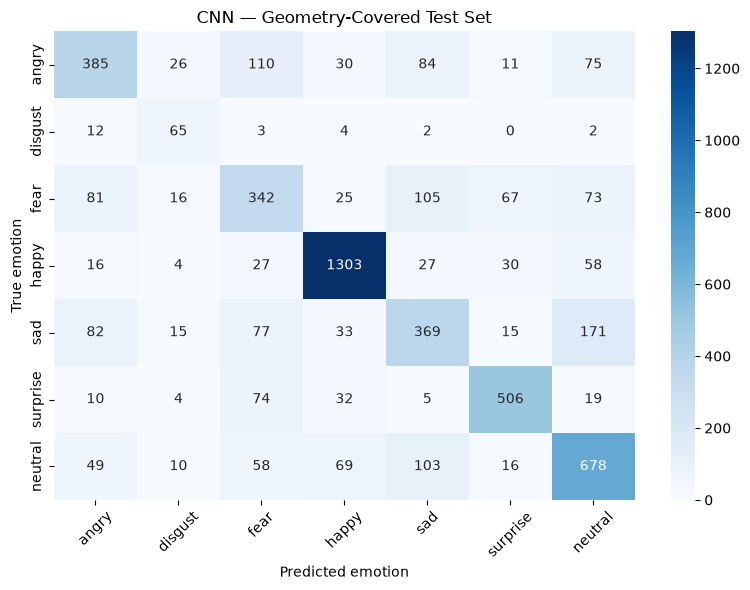


GEOMETRY CLASSIFICATION REPORT
              precision    recall  f1-score   support

       angry       0.46      0.47      0.46       721
     disgust       0.76      0.39      0.51        88
        fear       0.47      0.22      0.30       709
       happy       0.78      0.78      0.78      1465
         sad       0.35      0.35      0.35       762
    surprise       0.64      0.74      0.68       650
     neutral       0.48      0.61      0.54       983

    accuracy                           0.56      5378
   macro avg       0.56      0.51      0.52      5378
weighted avg       0.56      0.56      0.55      5378



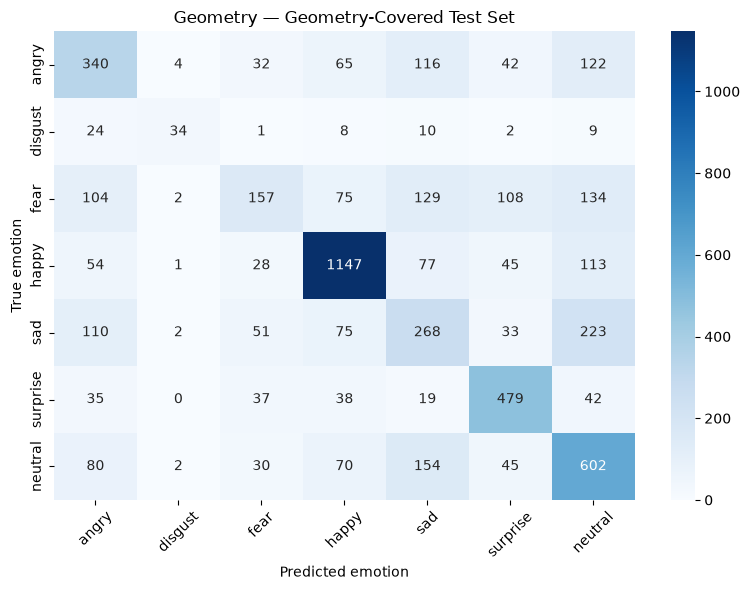


FUSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

       angry       0.62      0.55      0.59       721
     disgust       0.53      0.73      0.62        88
        fear       0.53      0.47      0.50       709
       happy       0.87      0.89      0.88      1465
         sad       0.55      0.50      0.53       762
    surprise       0.79      0.81      0.80       650
     neutral       0.63      0.72      0.67       983

    accuracy                           0.69      5378
   macro avg       0.65      0.67      0.65      5378
weighted avg       0.69      0.69      0.69      5378



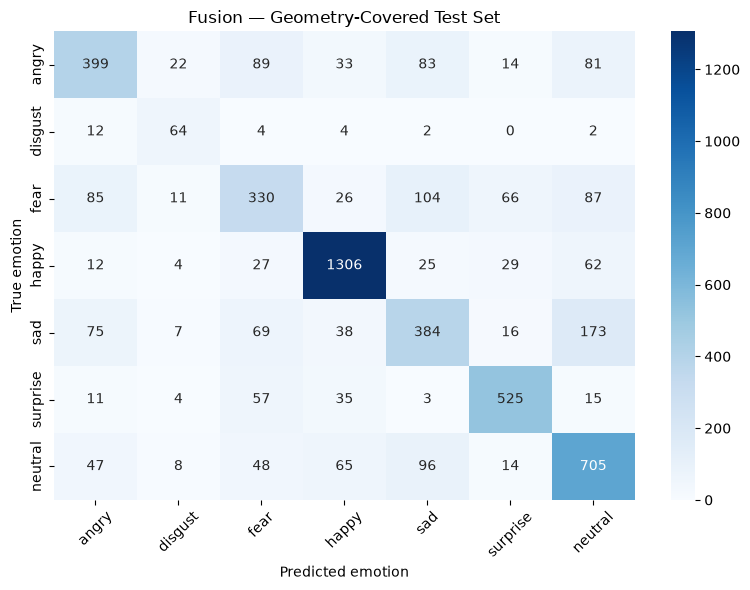

In [16]:
for model_name, predictions in covered_predictions.items():
    print(f"\n{model_name.upper()} CLASSIFICATION REPORT")
    print(classification_report(
        y_test_covered,
        predictions,
        labels=CNN_CLASSES,
        target_names=CNN_CLASSES,
        zero_division=0
    ))

    cm = confusion_matrix(y_test_covered, predictions, labels=CNN_CLASSES)
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=CNN_CLASSES, yticklabels=CNN_CLASSES, ax=ax
    )
    ax.set_title(f"{model_name} — Geometry-Covered Test Set")
    ax.set_xlabel("Predicted emotion")
    ax.set_ylabel("True emotion")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

## 15. Full-test hybrid with CNN fallback

In [17]:
cnn_all_probs = cnn_test[
    [f"cnn_{emotion}" for emotion in CNN_CLASSES]
].to_numpy(dtype=np.float64)

cnn_all_predictions = np.asarray(CNN_CLASSES)[np.argmax(cnn_all_probs, axis=1)]

final_hybrid_predictions = cnn_all_predictions.copy()
geometry_mask = cnn_test["geometry_available"].to_numpy(dtype=bool)
final_hybrid_predictions[geometry_mask] = covered_predictions["Fusion"]

y_test_all = cnn_test["emotion"].astype(str).to_numpy()

full_test_results = []
for model_name, predictions in {
    "CNN only": cnn_all_predictions,
    "Hybrid (fusion + CNN fallback)": final_hybrid_predictions,
}.items():
    full_test_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_all, predictions),
        "Macro F1": f1_score(y_test_all, predictions, labels=CNN_CLASSES, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_test_all, predictions, labels=CNN_CLASSES, average="weighted", zero_division=0),
    })

full_test_results_df = pd.DataFrame(full_test_results)
print("Total test images:", len(cnn_test))
print("Fusion used:", int(geometry_mask.sum()))
print("CNN fallback used:", int((~geometry_mask).sum()))
print("Geometry coverage:", f"{geometry_mask.mean() * 100:.2f}%")
display(full_test_results_df.round(4))

print("\nCOMPLETE HYBRID CLASSIFICATION REPORT")
print(classification_report(
    y_test_all,
    final_hybrid_predictions,
    labels=CNN_CLASSES,
    target_names=CNN_CLASSES,
    zero_division=0
))

Total test images: 7178
Fusion used: 5378
CNN fallback used: 1800
Geometry coverage: 74.92%


,Model,Accuracy,Macro F1,Weighted F1
0,CNN only,0.6562,0.6248,0.6552
1,Hybrid (fusion + CNN fallback),0.6652,0.6367,0.6630



COMPLETE HYBRID CLASSIFICATION REPORT
              precision    recall  f1-score   support

       angry       0.62      0.56      0.59       958
     disgust       0.47      0.70      0.57       111
        fear       0.49      0.46      0.48      1024
       happy       0.84      0.88      0.86      1774
         sad       0.55      0.53      0.54      1247
    surprise       0.79      0.78      0.78       831
     neutral       0.62      0.66      0.64      1233

    accuracy                           0.67      7178
   macro avg       0.63      0.65      0.64      7178
weighted avg       0.66      0.67      0.66      7178



## 16. Save results

In [18]:
alpha_results.to_csv(RESULTS_DIR / "fusion_alpha_validation_results.csv", index=False)
covered_results_df.to_csv(RESULTS_DIR / "fusion_geometry_covered_test_comparison.csv", index=False)
full_test_results_df.to_csv(RESULTS_DIR / "fusion_full_test_comparison.csv", index=False)

predictions_to_save = cnn_test[["image", "emotion", "geometry_available"]].copy()
predictions_to_save["cnn_prediction"] = cnn_all_predictions
predictions_to_save["hybrid_prediction"] = final_hybrid_predictions
predictions_to_save.to_csv(
    RESULTS_DIR / "fusion_complete_test_predictions.csv",
    index=False
)

hybrid_report = classification_report(
    y_test_all,
    final_hybrid_predictions,
    labels=CNN_CLASSES,
    target_names=CNN_CLASSES,
    output_dict=True,
    zero_division=0
)
pd.DataFrame(hybrid_report).transpose().to_csv(
    RESULTS_DIR / "fusion_complete_test_classification_report.csv"
)

print("Evaluation files saved in:", RESULTS_DIR)

Evaluation files saved in: c:\Users\HP\Documents\MiniProject\results


## 17. Load standalone fusion module

In [19]:
import sys

module_path = PROJECT_DIR / "fusion_model.py"
if not module_path.is_file():
    raise FileNotFoundError(f"fusion_model.py not found: {module_path}")

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from fusion_model import FacialEmotionFusion

fusion_system = FacialEmotionFusion(project_dir=PROJECT_DIR)

print("Standalone fusion module initialized.")
print("CNN input:", fusion_system.cnn_model.input_shape)
print("Fusion alpha:", fusion_system.alpha)
print("Geometry features:", len(fusion_system.feature_columns))

Standalone fusion module initialized.
CNN input: (None, 48, 48, 1)
Fusion alpha: 0.6
Geometry features: 25


## 18. Sample prediction

In [20]:
sample_image_path = TEST_DIR / "happy" / "PrivateTest_10077120.jpg"

if sample_image_path.is_file():
    sample_result = fusion_system.predict(sample_image_path)
    print("Predicted emotion:", sample_result["emotion"])
    print("Confidence:", f"{sample_result['confidence']:.2%}")
    print("Method:", sample_result["method"])
    print("Geometry available:", sample_result["geometry_available"])
    print("Probabilities:", sample_result["probabilities"])
else:
    print("Update sample_image_path to an existing FER-2013 image before testing.")

Predicted emotion: happy
Confidence: 93.04%
Method: cnn_geometry_fusion
Geometry available: True
Probabilities: {'angry': 0.008926193613796225, 'disgust': 0.007801055598428523, 'fear': 0.015894950793856603, 'happy': 0.9304177821435944, 'sad': 0.013612938872147387, 'surprise': 0.00869409595821087, 'neutral': 0.01465298301996597}


## Notes

Alpha is selected on validation data only. Test data is used only for final evaluation.